In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

/Users/smsoriano/miniforge3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '6104816f'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/Users/smsoriano/miniforge3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to 'ea355755'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/Users/smsoriano/miniforge3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'b134f8b7-4527-44b2-95f8-2e55880dd4f0' detected. Corrected to 'd8c1c52e'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATED LINK**
https://github.com/ssoriano22/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [2]:
# FINAL CODE

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

**Dataset 1:** New York Oil Spills Data

This dataset tracks occurances of oil spills in New York (NY) state from 2015 to 2026. Each row is a single spill event of a single material with an ID number, and information on that spill's site, location, date of occurance, date of report, date of closure, source and/or cause, and whether the spill was near a body of water. Reporting and documentation of these spill events by the responsible party is required by NY state law.

New York State Department of Environmental Conservation. (October 19, 2015). Spill Incidents. Data.NY.gov. Retrieved November 2, 2026, from https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data.

**Dataset 2:** TIGER shapefile (US Counties and equivalent)

This dataset contains geographic information for US counties (and equivalent) from the US Census Bureau, updated through October 14, 2026. One row contains general, non-demographic information for a single county (or equivalent), including unique identifiers, area dimensions and measurements, and geometries.

U.S. Census Bureau. (October 14, 2026). 2026 TIGER/Line shapefiles. U.S. Department of Commerce. Retrieved November 2, 2026, from https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html.

## 3. Import libraries

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Display all columns when looking at dfs
pd.set_option('display.max_columns', None)

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [4]:
# Load spill csv
fp = os.path.join('data', 'Spill_Incidents_20261102.csv')
spills = pd.read_csv(fp)

# Load TIGER shapefile - county
fp2 = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp2)


<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

This `spills` dataset has 574732 rows and 20 columns, as the metadata stated. The following columns have at least some missing data: `Program Facility Name`, `Street 1`, `Street 2`, `Locality`, `ZIP Code`, `Spill Date`, `Received Date`, `Waterbody`, `Close Date`, and `Units`. All other columns shown in the `info()` result below have data in all 574732 rows. The majority of columns are object (string) type, except for the following int64 type columns: `Spill Number`, `SWIS Code`, and `DEC Region`. Some columns - `ZIP Code`, `Quantity`, and `Recovered` - seem like they should be int64 or float64 type instead of strings. Also, the three date columns mentioned above will need to be transformed into datetime types. The unique values in the `Material Family` column are 'Other', 'Petroleum', 'Hazardous Material', 'Oxygenates.' There are 87 unique values in the `County` column - these unique values are displayed below.

In [5]:
# Confirm spills dimensions
spills.shape

(574732, 20)

In [6]:
#a. Check the dataframe's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [7]:
#b. Check the data types of the columns - and other info
spills.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574732 entries, 0 to 574731
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   Spill Number           574732 non-null  int64 
 1   Program Facility Name  574726 non-null  object
 2   Street 1               574598 non-null  object
 3   Street 2               44735 non-null   object
 4   Locality               573581 non-null  object
 5   County                 574732 non-null  object
 6   ZIP Code               57909 non-null   object
 7   SWIS Code              574732 non-null  int64 
 8   DEC Region             574732 non-null  int64 
 9   Spill Date             574581 non-null  object
 10  Received Date          574229 non-null  object
 11  Contributing Factor    574732 non-null  object
 12  Waterbody              47992 non-null   object
 13  Source                 574732 non-null  object
 14  Close Date             562311 non-null  object
 15  

In [8]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [9]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [10]:
# Simplify column names
spills.columns = (spills.columns.str.lower() # Lowercase
                                .str.replace(" ", "_") # Replace spaces w/ "_"
)
spills.columns 

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [11]:
# Update the 3 date columns from object to datetime type
spills['spill_date'] = pd.to_datetime(spills['spill_date'])
spills['received_date'] = pd.to_datetime(spills['received_date'])
spills['close_date'] = pd.to_datetime(spills['close_date'])

# Confirm type change
spills.info()
spills.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574732 entries, 0 to 574731
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   spill_number           574732 non-null  int64         
 1   program_facility_name  574726 non-null  object        
 2   street_1               574598 non-null  object        
 3   street_2               44735 non-null   object        
 4   locality               573581 non-null  object        
 5   county                 574732 non-null  object        
 6   zip_code               57909 non-null   object        
 7   swis_code              574732 non-null  int64         
 8   dec_region             574732 non-null  int64         
 9   spill_date             574581 non-null  datetime64[ns]
 10  received_date          574229 non-null  datetime64[ns]
 11  contributing_factor    574732 non-null  object        
 12  waterbody              47992 non-null   obje

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,2001-10-10,2001-10-10,Unknown,NaN,Unknown,2001-10-15,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,2004-08-21,2004-08-21,Other,EAST RIVER,Unknown,2004-09-17,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,2004-08-21,2004-08-21,Other,EAST RIVER,Unknown,2004-09-17,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,2002-08-02,2002-08-02,Equipment Failure,NaN,Commercial/Industrial,2002-10-28,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,2003-01-20,2003-01-20,Traffic Accident,NaN,Commercial/Industrial,2003-01-22,transformer oil,Petroleum,6,Gallons,6


In [12]:
# Check why quantity column is an object - contains comma numbers (i.e. "1,126")
spills['quantity'].unique()
# Fix quantity column type
spills['quantity'] = (spills['quantity'].str.replace(",","") # Remove ","
                                        .astype(float) # Coerce to float
)
# Confirm type change
spills.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574732 entries, 0 to 574731
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   spill_number           574732 non-null  int64         
 1   program_facility_name  574726 non-null  object        
 2   street_1               574598 non-null  object        
 3   street_2               44735 non-null   object        
 4   locality               573581 non-null  object        
 5   county                 574732 non-null  object        
 6   zip_code               57909 non-null   object        
 7   swis_code              574732 non-null  int64         
 8   dec_region             574732 non-null  int64         
 9   spill_date             574581 non-null  datetime64[ns]
 10  received_date          574229 non-null  datetime64[ns]
 11  contributing_factor    574732 non-null  object        
 12  waterbody              47992 non-null   obje

In [13]:
# Check why recovered column is an object - contains comma numbers (i.e. "1,126")
spills['recovered'].unique()
# Fix recovered column type
spills['recovered'] = (spills['recovered'].str.replace(",","") # Remove ","
                                          .astype(float) # Coerce to float
)
# Confirm type change
spills.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574732 entries, 0 to 574731
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   spill_number           574732 non-null  int64         
 1   program_facility_name  574726 non-null  object        
 2   street_1               574598 non-null  object        
 3   street_2               44735 non-null   object        
 4   locality               573581 non-null  object        
 5   county                 574732 non-null  object        
 6   zip_code               57909 non-null   object        
 7   swis_code              574732 non-null  int64         
 8   dec_region             574732 non-null  int64         
 9   spill_date             574581 non-null  datetime64[ns]
 10  received_date          574229 non-null  datetime64[ns]
 11  contributing_factor    574732 non-null  object        
 12  waterbody              47992 non-null   obje

In [14]:
# Check why zip_code column is an object - contains NaN values
spills['zip_code'].unique()
# Try to coerce to int64
# spills['zip_code'] = spills['zip_code'].astype('Int64')

# Coerce will not work - some zip_code values include postal code (i.e. "14622-1750")
# Will keep this column as object/string

array([nan, '14543', '14818', ..., '12873', '12175', '145813'],
      dtype=object)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [15]:
# Select spills (rows) with spill_date btwn 1-1-2023 and 12-31-2023
petr_23 = spills.loc[(spills['spill_date'].dt.year == 2023) &
                      (spills['material_family'] == "Petroleum")]
# Confirm selection applied
petr_23.head()

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
70,2307439,#2 F/O IN GULLY (SMITH RESIDENCE),3666 MIDDLE ROAD,NaN,BURDETT,Schuyler,14818,4926,8,2023-12-08,2023-12-08,Traffic Accident,NaN,Tank Truck,2024-12-18,diesel,Petroleum,300.0,Gallons,0.0
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,diesel,Petroleum,0.0,NaN,0.0
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil,Petroleum,0.0,Gallons,0.0
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,gasoline,Petroleum,0.0,NaN,0.0
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0.0,NaN,0.0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [16]:
# Print statement checks for material_family and date selection
print(f"The petr_23 subset of the spills dataset only contains the year {petr_23['spill_date'].dt.year.unique()}.")
print(f"The oldest spill in the petr_23 subset was on {petr_23['spill_date'].min().date()}.")
print(f"The newest spill in the petr_23 subset was on {petr_23['spill_date'].max().date()}.")

The petr_23 subset of the spills dataset only contains the year [2023].
The oldest spill in the petr_23 subset was on 2023-01-01.
The newest spill in the petr_23 subset was on 2023-12-31.


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [17]:
# Assert check for material_family selection
assert (petr_23['material_family'] == "Petroleum").all()


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

The number of rows in the `petr_23` subset - 8468 - is not equal to the number of unique spill identifiers in the `spill_number` column - 8228. One possible reason for this is in the case of one spill consisting of multiple materials. In such cases, each material has its own row, but all materials composing a single spill share the same `spill_number` value.

In [18]:
# Print statements to check number of rows and number of unique spill_number values in petr_23
print(f"The subset petr_23 has {petr_23.shape[0]} rows.")
print(f"The subset petr_23 has {petr_23['spill_number'].nunique()} unique spill_number ID values.")

The subset petr_23 has 8468 rows.
The subset petr_23 has 8228 unique spill_number ID values.


In [19]:
# Explore spill_number and material_name values per row
petr_23.head()

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
70,2307439,#2 F/O IN GULLY (SMITH RESIDENCE),3666 MIDDLE ROAD,NaN,BURDETT,Schuyler,14818,4926,8,2023-12-08,2023-12-08,Traffic Accident,NaN,Tank Truck,2024-12-18,diesel,Petroleum,300.0,Gallons,0.0
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,diesel,Petroleum,0.0,NaN,0.0
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil,Petroleum,0.0,Gallons,0.0
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,gasoline,Petroleum,0.0,NaN,0.0
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0.0,NaN,0.0


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [20]:
# Calculate number of unique spill_number values per county
spills_per_county = petr_23.groupby('county').agg({'spill_number':'nunique'})
# Reset index of summary df and rename count column for autograder
spills_per_county = spills_per_county.reset_index().rename(columns = {'county':'county',
                                                                      'spill_number':'n_spills'})



# Confirm new df meets specs
spills_per_county


,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [21]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

This counties geo-dataframe has 3235 rows and 19 columns. All columns are object (string) type, except for two int64 columns - `ALAND` and `AWATER` - and the one geometry column. The following columns have at least some missing values: `CSAFP`, `CBSAFP`, and `METDIVFP`. The current crs of this geo-dataframe is ESPG:4269, and the initial plot of the geometries displays a map of the US, including Alaska (and its islands), Hawaii, and other island territories.

In [22]:
counties.shape

(3235, 19)

In [23]:
# a Check head of geo-dataframe counties
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [24]:
# b Check counties column info
counties.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 3235 entries, 0 to 3234
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   STATEFP   3235 non-null   object  
 1   COUNTYFP  3235 non-null   object  
 2   COUNTYNS  3235 non-null   object  
 3   GEOID     3235 non-null   object  
 4   GEOIDFQ   3235 non-null   object  
 5   NAME      3235 non-null   object  
 6   NAMELSAD  3235 non-null   object  
 7   LSAD      3235 non-null   object  
 8   CLASSFP   3235 non-null   object  
 9   MTFCC     3235 non-null   object  
 10  CSAFP     1341 non-null   object  
 11  CBSAFP    1915 non-null   object  
 12  METDIVFP  139 non-null    object  
 13  FUNCSTAT  3235 non-null   object  
 14  ALAND     3235 non-null   int64   
 15  AWATER    3235 non-null   int64   
 16  INTPTLAT  3235 non-null   object  
 17  INTPTLON  3235 non-null   object  
 18  geometry  3235 non-null   geometry
dtypes: geometry(1), int64(2), object(16)
mem

In [25]:
# c Check counties current crs
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [26]:
# d Plot counties initially
counties.plot()

<Axes: >

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

Index(['statefp', 'countyfp', 'countyns', 'geoid', 'geoidfq', 'name',
       'namelsad', 'lsad', 'classfp', 'mtfcc', 'csafp', 'cbsafp', 'metdivfp',
       'funcstat', 'aland', 'awater', 'intptlat', 'intptlon', 'geometry'],
      dtype='object')

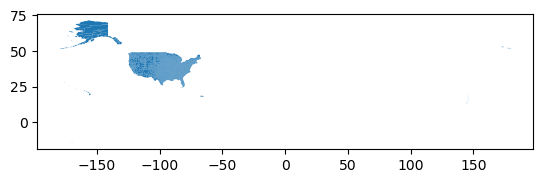

In [27]:
# Simplify counties column names
counties.columns = counties.columns.str.lower() # Lowercase
counties.columns

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [28]:
# Create NY subset of counties - NY STATEFP = 36 according to metadata
ny_counties = counties.loc[counties['statefp'] == "36"]
# Confirm selection was applied
ny_counties.head()

,statefp,countyfp,countyns,geoid,geoidfq,name,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
258,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461..."
259,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084..."
338,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697..."
352,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999..."
492,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012..."


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [29]:
# Print unique ny_counties county names
print(ny_counties['name'].unique())

['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [30]:
# Print unique spills_per_county county names
print(spills_per_county['county'].unique())

# Output is alphabetical, unlike ny_counties output above

['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [31]:
# Find county names only in spills_per_county, not ny_counties
diff_names_spills = np.setdiff1d(spills_per_county['county'],ny_counties['name'])
# Confirm array of strings output
diff_names_spills


array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [32]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [33]:
# Find county names only in ny_counties, not spills_per_county
diff_names_ny = np.setdiff1d(ny_counties['name'],spills_per_county['county'])
# Confirm array of strings output
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [34]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [35]:
# e. Check the number of spills in 'Tuscarora Indian Reservation' and 'Onondaga Indian Reservation'
TIR_n_spill = spills_per_county.loc[(spills_per_county['county'] == 'Tuscarora Indian Reservation') |
                                    (spills_per_county['county'] == 'Onondaga Indian Reservation')]
TIR_n_spill

,county,n_spills
35,Onondaga Indian Reservation,1
58,Tuscarora Indian Reservation,2


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [36]:
# Update spills_per_county['county'] == 'St Lawrence' to 'St. Lawrence'
spills_per_county.loc[spills_per_county['county'] == 'St Lawrence', 'county'] = 'St. Lawrence'

# Check that old value is not in any row of the county column
assert ~ spills_per_county['county'].isin(['St Lawrence']).any()

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [37]:
# a
# Confirm columns to merge on in each df
ny_counties['name']
spills_per_county['county']

0          Albany
1        Allegany
2           Bronx
3          Broome
4     Cattaraugus
         ...     
61     Washington
62          Wayne
63    Westchester
64        Wyoming
65          Yates
Name: county, Length: 66, dtype: object

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [38]:
# Merge spills_per_county and ny_counties by 
ny_spills = (pd.merge(spills_per_county,ny_counties,left_on='county',right_on='name', how = 'inner')
             .drop(columns = 'name')
)
# Compare dimensions of each df
print("spills_per_county dimensions:",spills_per_county.shape)
print("ny_counties dimensions:",ny_counties.shape)
print("ny_spills dimensions:",ny_spills.shape)
ny_spills.head()

spills_per_county dimensions: (66, 2)
ny_counties dimensions: (62, 19)
ny_spills dimensions: (62, 20)


,county,n_spills,statefp,countyfp,countyns,geoid,geoidfq,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
0,Albany,224,36,001,00974099,36001,0500000US36001,Albany County,06,H1,G4020,104,10580,None,A,1354273428,26971923,+42.5882401,-073.9740095,"POLYGON ((-73.96379 42.44162, -73.96666 42.441..."
1,Allegany,32,36,003,00974100,36003,0500000US36003,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518..."
2,Bronx,152,36,005,00974101,36005,0500000US36005,Bronx County,06,H6,G4020,408,35620,35614,C,109301867,39287123,+40.8487111,-073.8529390,"POLYGON ((-73.93381 40.88221, -73.93365 40.882..."
3,Broome,80,36,007,00974102,36007,0500000US36007,Broome County,06,H1,G4020,None,13780,None,A,1827626584,25078248,+42.1619773,-075.8302833,"POLYGON ((-75.74223 41.99805, -75.75080 41.997..."
4,Cattaraugus,45,36,009,00974103,36009,0500000US36009,Cattaraugus County,06,H1,G4020,160,36460,None,A,3388177044,36783591,+42.2390986,-078.6623320,"POLYGON ((-78.69725 41.99867, -78.69881 41.998..."


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [39]:
# Create array of dropped county names during inner merge
dropped_counties = np.setdiff1d(spills_per_county['county'],ny_spills['county'])
# Subset spills_per_county to only contain those dropped records
dropped_counties_spills = spills_per_county.loc[spills_per_county['county'].isin(dropped_counties)]
# Display dropped records
dropped_counties_spills

,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

Since we are concerned with mapping NY state oil spills, dropping the New Jersey and Pennsylvania records should not cause a problem. However, the two reservations are located within NY state, despite the US Census Bureau omitting them from their data set, and ideally their spill data should be included in the map we are creating.

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [ ]:
# Get index values of each reservation from dropped_counties_spills
# Note: .index[0] returns only the index, instead of both the index and the type
TIR_index = dropped_counties_spills[dropped_counties_spills['county'] == 'Tuscarora Indian Reservation'].index[0]
OD_index = dropped_counties_spills[dropped_counties_spills['county'] == 'Onondaga Indian Reservation'].index[0]

# Retrieve n_spill counts for each reservation from dropped_counties_spills
TIR_nspill = dropped_counties_spills.at[TIR_index, 'n_spills']
OD_nspill = dropped_counties_spills.at[OD_index, 'n_spills']

# Get index values for Niagara and Onondaga county in ny_spills
NIA_index = ny_spills[ny_spills['county'] == 'Niagara'].index[0]
ODC_index = ny_spills[ny_spills['county'] == 'Onondaga'].index[0]

# Check NIA and ODC n_spill values before adding reservation n_spill counts
print("Before:")
print("NIA:", ny_spills.at[NIA_index,'n_spills'])
print("ODC:",ny_spills.at[ODC_index,'n_spills'])

# Add TIR_nspill to ny_spills Niagara n_spills
# Note: the type:ignore were added because Pylance was upset about this addition - but mathematically this IS working
ny_spills.at[NIA_index,'n_spills'] += int(TIR_nspill) # type: ignore 
ny_spills.at[ODC_index,'n_spills'] += int(OD_nspill) # type: ignore 

Before:
NIA: 97
ODC: 214


In [ ]:
# Check NIA was incremented by 2 and ODC incremented by 1 after adding reservation n_spill counts
print("After:")
print("NIA:", ny_spills.at[NIA_index,'n_spills'])
print("ODC:",ny_spills.at[ODC_index,'n_spills'])

After:
NIA: 99
ODC: 215


dtype('int64')

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



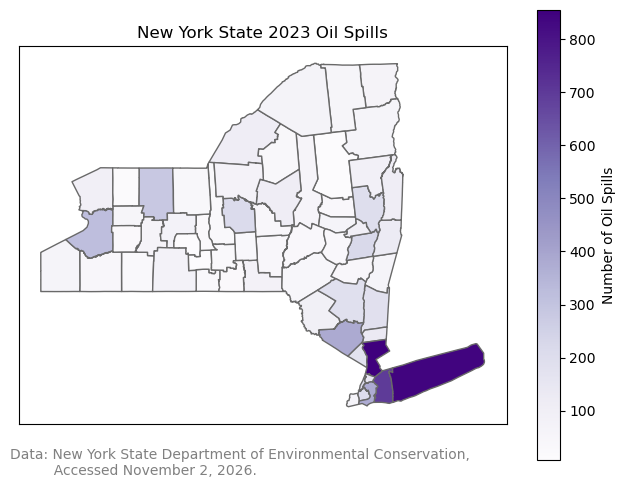

In [74]:
# Make ny_spills a geodataframe
ny_spills_geo = gpd.GeoDataFrame(ny_spills,geometry='geometry')

# Initialize empty figure
fig, ax = plt.subplots()

# Add data to axes
ny_spills_geo.plot(ax = ax,         # Add plot to axes
                   edgecolor = "dimgrey", # Color point outline
                   column = ny_spills['n_spills'],  # Assign column for color
                   cmap = 'Purples', # Define color palette
                   legend = True, # Add color legend
                   legend_kwds = {'label':'Number of Oil Spills'} # Add legend label
                 )

# Update axes 
ax.set_title('New York State 2023 Oil Spills')
# Remove xticks and yticks
ax.set_xticks([])
ax.set_yticks([])

# Add data caption
plt.figtext(0.01, 0.0,"Data: New York State Department of Environmental Conservation,\n          Accessed November 2, 2026.", color = "grey")

# Display figure
plt.tight_layout()
plt.show()



b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.